# Intro to Embeddings: Classifying Amazon Reviews

In this notebook you will learn:

1. **What an embedding is**: a list of numbers that captures the *meaning* of a piece of text.
2. **How to compare embeddings**: texts with similar meaning have similar numbers.
3. **How to build a classifier with no training data**: decide whether an Amazon review is *positive* or *negative* by checking which description it is closest to.

Based on the OpenAI Cookbook example [*Zero-shot classification with embeddings*](https://developers.openai.com/cookbook/examples/zero-shot_classification_with_embeddings).

> **Before you start:** make sure there is a `.env` file next to this notebook containing `OPENAI_API_KEY=...`.

## Step 1: Setup

In [1]:
# Uncomment and run once if these packages are not installed yet
# %pip install -q openai python-dotenv pandas numpy scikit-learn matplotlib

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()        # reads OPENAI_API_KEY from the .env file
client = OpenAI()    # connects to the OpenAI API

MODEL = "text-embedding-3-small"

## Step 2: Your first embedding

An **embedding model** turns text into a long list of numbers (a *vector*). We can't read the numbers ourselves, but texts that mean similar things end up with similar lists.

Let's write a small helper function and try it.

In [3]:
def embed(texts):
    """Turn a list of texts into a list of embeddings (one vector per text)."""
    response = client.embeddings.create(model=MODEL, input=texts)
    return [np.array(item.embedding) for item in response.data]

vector = embed(["I love this coffee!"])[0]

print("Number of values in the embedding:", len(vector))
print("The first 5 values:", vector[:5].round(4))

Number of values in the embedding: 1536
The first 5 values: [-0.0443 -0.0314 -0.0405 -0.0301 -0.0415]


Every text, short or long, becomes **1,536 numbers**. On their own the numbers mean nothing to us. What matters is how they **compare** to other embeddings.

## Step 3: Measuring similarity

To compare two embeddings we use **cosine similarity**:

- close to **1** → very similar meaning
- lower → less related

It is the standard way to compare embeddings, and it takes one line of code.

In [4]:
def similarity(a, b):
    """Cosine similarity between two vectors."""
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

sentences = [
    "This coffee tastes amazing.",
    "What a delicious cup of coffee!",
    "The coffee was awful and bitter.",
    "My dog loves these treats.",
]
vectors = embed(sentences)

# Compare every sentence with every other sentence
table = pd.DataFrame(
    [[similarity(a, b) for b in vectors] for a in vectors],
    index=sentences, columns=[s[:20] + "…" for s in sentences],
)
table.round(2)

,This coffee tastes a…,What a delicious cup…,The coffee was awful…,My dog loves these t…
This coffee tastes amazing.,1.00,0.65,0.52,0.26
What a delicious cup of coffee!,0.65,1.00,0.48,0.23
The coffee was awful and bitter.,0.52,0.48,1.00,0.09
My dog loves these treats.,0.26,0.23,0.09,1.00


**What to notice:**
- The two positive coffee sentences are the most similar pair.
- The negative coffee sentence is still fairly close, because it is also about coffee.
- The dog sentence is the least similar to the coffee sentences.

Embeddings capture **topic** *and* **tone**.

### Seeing it in a picture

1,536 dimensions are impossible to draw, so we squash them down to 2 using **PCA** (a standard way to shrink data while keeping as much of the structure as possible). Words with related meanings should land near each other.

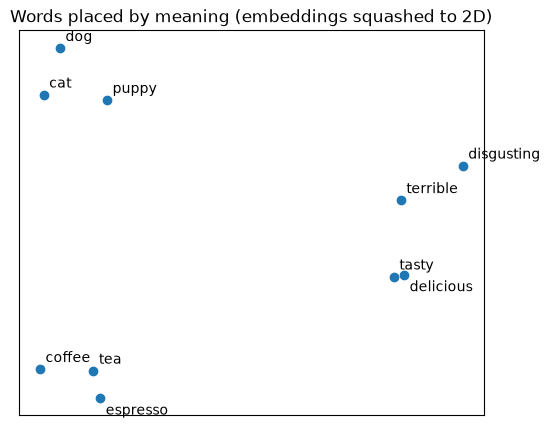

In [5]:
from sklearn.decomposition import PCA

words = ["dog", "cat", "puppy", "coffee", "tea", "espresso",
         "delicious", "tasty", "disgusting", "terrible"]
points = PCA(n_components=2).fit_transform(embed(words))

plt.figure(figsize=(6, 5))
plt.scatter(points[:, 0], points[:, 1])
for word, (x, y) in zip(words, points):
    # put a couple of labels below their dot so neighbours don't overlap
    offset = -12 if word in ("delicious", "espresso") else 5
    plt.annotate(word, (x, y), xytext=(4, offset), textcoords="offset points")
plt.title("Words placed by meaning (embeddings squashed to 2D)")
plt.xticks([]); plt.yticks([])
plt.show()

## Step 4: The classification idea

Here is the trick, called **zero-shot classification** ("zero" because we use zero labeled examples):

1. Write a short **description** for each class.
2. Embed the descriptions.
3. For each review, find the description it is **most similar** to. That is the prediction.

```
review  ──►  embedding ──┐
                         ├──►  compare  ──►  closest description wins
descriptions ► embeddings┘
```

Let's try it on a single review first.

In [6]:
labels = {
    "negative": "An Amazon review with a negative sentiment.",
    "positive": "An Amazon review with a positive sentiment.",
}
label_vectors = embed(list(labels.values()))   # [negative vector, positive vector]

review = "These chips arrived stale and tasted like cardboard."
review_vector = embed([review])[0]

for name, label_vector in zip(labels, label_vectors):
    print(f"Similarity to {name}: {similarity(review_vector, label_vector):.3f}")

Similarity to negative: 0.298
Similarity to positive: 0.165


The review is more similar to the **negative** description, so we predict *negative*. Similarity values for sentences like these are often modest (well below 1), but all we need is to know which one is bigger.

## Step 5: Load real Amazon reviews

We use 1,000 Amazon Fine Food reviews from the OpenAI Cookbook. Each one has a star rating (1–5), and the embeddings have **already been calculated** for us with the same model, which saves time and money.

In [7]:
URL = "https://raw.githubusercontent.com/openai/openai-cookbook/main/examples/data/fine_food_reviews_with_embeddings_1k.csv"
reviews = pd.read_csv(URL)

# The embeddings are stored as text like "[0.01, -0.02, ...]", so convert them back to numbers
reviews["embedding"] = reviews["embedding"].apply(lambda text: np.array(json.loads(text)))

reviews[["Score", "Summary", "Text"]].head()

,Score,Summary,Text
0,5,where does one start...and stop... with a tre...,Wanted to save some to bring to my Chicago fam...
1,4,"Good, but not Wolfgang Puck good","Honestly, I have to admit that I expected a li..."
2,1,Should advertise coconut as an ingredient more...,"First, these should be called Mac - Coconut ba..."
3,5,Best tomato soup,I have a hard time finding packaged food of an...
4,1,Should advertise coconut as an ingredient more...,"First, these should be called Mac - Coconut ba..."


The stars tell us the **true answer**, which we only use to *check* our classifier, never to train it:

| Stars | Sentiment |
|---|---|
| 1–2 | negative |
| 3 | neutral (we skip these to keep it simple) |
| 4–5 | positive |

In [8]:
reviews = reviews[reviews["Score"] != 3].copy()
reviews["true_label"] = np.where(reviews["Score"] >= 4, "positive", "negative")

reviews["true_label"].value_counts()

true_label
positive    789
negative    136
Name: count, dtype: int64

## Step 6: Classify every review

In [9]:
def classify(vector):
    """Return the label whose description is most similar to this embedding."""
    scores = [similarity(vector, label_vector) for label_vector in label_vectors]
    return list(labels)[np.argmax(scores)]

reviews["predicted"] = reviews["embedding"].apply(classify)

reviews[["Score", "true_label", "predicted", "Summary"]].head(10)

,Score,true_label,predicted,Summary
0,5,positive,positive,where does one start...and stop... with a tre...
1,4,positive,negative,"Good, but not Wolfgang Puck good"
2,1,negative,negative,Should advertise coconut as an ingredient more...
3,5,positive,positive,Best tomato soup
4,1,negative,negative,Should advertise coconut as an ingredient more...
5,5,positive,positive,"Loved these gluten free healthy bars, saved $$..."
6,5,positive,positive,These fresh berries are truly MIRACULOUS!!!
7,5,positive,positive,Baconnaise
8,5,positive,positive,"Loved these gluten free healthy bars, saved $$..."
9,1,negative,positive,Cute


## Step 7: How well did it do?

In [10]:
accuracy = (reviews["predicted"] == reviews["true_label"]).mean()
print(f"Accuracy: {accuracy:.1%}")

# Rows = true answer, columns = what the model predicted
pd.crosstab(reviews["true_label"], reviews["predicted"])

Accuracy: 94.9%


predicted,negative,positive
true_label,,
negative,131,5
positive,42,747


**Reading the table:** the diagonal (negative/negative and positive/positive) holds the correct answers. Everything else is a mistake.

All of this with **zero training examples**, just two sentences describing the classes!

### Let's look at some mistakes

In [11]:
mistakes = reviews[reviews["predicted"] != reviews["true_label"]]
for _, row in mistakes.head(5).iterrows():
    print(f"{row.Score}★  true: {row.true_label}  predicted: {row.predicted}")
    print(f"   {row.Summary} | {row.Text[:150]}...\n")

4★  true: positive  predicted: negative
   Good, but not Wolfgang Puck good | Honestly, I have to admit that I expected a little better. That's not to say that this is bad coffee - in fact it's quite bold without being too acidi...

1★  true: negative  predicted: positive
   Cute | For some reason I thought that you got three "pops" but you only get one.  For the price I paid for the Puff Pop and shipping it was just a little too...

5★  true: positive  predicted: negative
   Great coffee, not bitter. | I'm not a big fan of the green mountain coffees, because they all seem to be bitter.  This is a nice brew that is strong enough for me without being b...

4★  true: positive  predicted: negative
   yummy cookies! | We've ordered for them every month and only once the package inside the seal had a small hole and wasn't as fresh....

4★  true: positive  predicted: negative
   yummy cookies! | We've ordered for them every month and only once the package inside the seal had a small hole and

Common causes of mistakes:
- **Mixed feelings**: "good, but not as good as I expected" gets 4★ but reads as a complaint.
- **Negative words used positively**: "not bitter" contains *bitter*, which pulls the review toward negative.
- **Small complaints in happy reviews**: a 4★ review that mentions one bad package.

These are hard for people too!

## Step 8: Try it yourself

In [12]:
def classify_text(text):
    return classify(embed([text])[0])

my_reviews = [
    "Best snack I've bought all year, my kids love it.",
    "The package was crushed and half the cookies were broken.",
    "Way too sweet, I couldn't finish it.",
    # ✏️ Add your own review here!
]
for text in my_reviews:
    print(f"{classify_text(text):>8}  ←  {text}")

positive  ←  Best snack I've bought all year, my kids love it.


negative  ←  The package was crushed and half the cookies were broken.
negative  ←  Way too sweet, I couldn't finish it.


## Exercises

1. **Change the wording.** Replace the descriptions with just `"positive"` and `"negative"` and rerun Steps 4–7. Does accuracy go up or down? Why might a full sentence work better?
2. **Add a third class.** Put the 3-star reviews back (skip the filter in Step 5), add a `"neutral"` description, and label 3★ as neutral. How does accuracy change?
3. **Classify by topic instead of sentiment.** Write descriptions like *"An Amazon review about coffee or tea."* or *"An Amazon review about pet food."* and look at which reviews end up in each topic.
4. **Explore similarity.** Add your own sentences to the table in Step 3. Can you find two sentences with different words but very high similarity?

## Recap

- An **embedding** turns text into a list of numbers that represents its meaning.
- **Cosine similarity** tells us how close two meanings are.
- **Zero-shot classification** = compare each text with a description of each class and pick the closest one. No labeled training data needed.
- Want to go further? See `amazon_reviews_zero_shot_classification.ipynb` for precision–recall curves, three classes, topics, and a comparison with a trained model.